# 09 — The full model: native gates, uniform noise on every qubit

## What this notebook is

Every ingredient built in 07–08, in one circuit:

| ingredient | from | here |
| --- | --- | --- |
| idle noise of trapped-ion form (Z only, linear `γ` and quadratic `c`) | 07 | yes |
| X-basis memory (the only one that sees Z noise) | 07 | yes |
| **Selene's native gates** (each CNOT is one `Rzz` plus single-qubit gates), noise on every native gate | 07b | yes |
| **every qubit has the same noise**, ancillas included, applied through time inside each round | 08 | yes |
| two-qubit errors on every two-qubit gate, data–ancilla included | 07, 08 | yes |
| readout error **measured**, never assumed | 08 | yes |

**How time runs through a round.** Selene's compiled round is scheduled into layers: each native
operation goes into the earliest layer after every earlier operation on its qubits (this moves
only operations on different qubits, so the circuit is unchanged; checked in §1). A round lasts
one time unit `t_R`; each of its L layers lasts `t_R / L`. After every layer, **every** qubit gets
the idle noise for that duration, and over the wait between rounds (`Δt − 1`) every qubit gets it
again.

Then 08's three questions:
- **(P1)** Is there still an optimal interval Δt\*?
- **(P2)** Does the circuit, read through its detection events, still look like the paper's model:
  a readout error that does not depend on Δt, and a data error that is a fixed per-round part plus
  the idle error of the wait?
- **(P3)** Does the paper's model, fed parameters **measured** at one interval, predict Δt\*?

And two more: how Δt\* moves as each ingredient is added (07 → 07b → 08 → 09), and 07's H2-ratio
check repeated on this model.

**Result.** With every ingredient in, the premise holds, and the numbers barely move:

| | result | § |
| --- | --- | --- |
| checks | noiseless: 0 events; the schedule leaves the error model **identical**; 18 layers per round at every d | 1 |
| **(P1)** interior optimum | yes, all 9 curves | 3 |
| **(P2)** readout independent of Δt | 0.995–1.003 × its Δt = 1 value, Δt = 1 to 16 | 2 |
| **(P2)** data error = per-round part + wait | 0.996–1.002 × prediction | 2 |
| **measured `b_read`** | 0.95–0.99 from gates alone; 1.05–1.09 with linear dephasing | 2 |
| **(P3)** Δt\* from one calibration at Δt = 1 | d = 3: +17% to +21%; d = 5: +4% to +9%; d = 7: −2% to +1% | 4 |
| Δt\* against 07 (textbook gates, data-only idle) | −0.4% to +14%; linear settings within ±1% | 5 |
| at H2's estimated ratio, **linear** idle | unchanged from 07: a short wait helps only at d = 3 (Δt = 2.29, +11–12%) | 6 |
| at H2's estimated ratio, **quadratic** idle | **changed**: a short wait (Δt ≈ 1.3) helps by 13–18%, but this follows from how the quadratic term is split in time, which is unresolved | 6 |

## 0. Setup

07's noise: H2-1E emulator ratios scaled ×4.76 (`p_2q = 5×10⁻³`), the same three idle settings as
08, `T = 192`, 07's Δt grids, 2 × 100,000 shots per point. `Rz` noiseless (07b, an assumption).

In [1]:
import sys, pathlib, time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'

sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from qec_timing.circuit_level import runcache
from qec_timing.circuit_level.stim_memory import idle_channel
from qec_timing.circuit_level.native_memory import NativeMemory, TimedNativeMemory
from qec_timing.circuit_level.timed_memory import (TimedMemory, phenomenological_circuit,
                                                   phenomenological_error, edge_probabilities,
                                                   layout_edges, xor)

pd.set_option('display.width', 220)
FIGDIR = pathlib.Path('figures')
BLUE, ORANGE, AQUA, GRAY, RED = '#1f5aa6', '#d9822b', '#2a9d8f', '#888888', '#c0392b'

H2 = dict(p1=1.89e-5, p2=1.05e-3, p_meas0=6e-4, p_meas1=1.39e-3, p_init=4e-5)
P2 = 5e-3
SCALE = P2 / H2['p2']
GATES = dict(p1=H2['p1'] * SCALE, p2=P2,
             p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']) * SCALE,
             p_init=H2['p_init'] * SCALE)
H2_GATES = dict(p1=H2['p1'], p2=H2['p2'], p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']),
                p_init=H2['p_init'])
T = 192
DISTANCES = (3, 5, 7)
SHOTS, SEEDS = 100_000, (1, 2)
KEYS = (('lin', 0.3), ('quad', 0.01), ('mixed', (0.3, 0.01)))
NOIDLE = ('lin', 0.0)
R_CAL, SHOTS_CAL = 20, 400_000
EXP = '09_native_uniform_noise'
EXP07, EXP07B, EXP08 = '07_dephasing_interval', '07b_native_dephasing', '08_uniform_noise_premise'
N_WORKERS = min(16, mp.cpu_count())
print({k: f'{v:.3g}' for k, v in GATES.items()}, f'{N_WORKERS} workers')

{'p1': '9e-05', 'p2': '0.005', 'p_meas': '0.00474', 'p_init': '0.00019'} 16 workers


In [2]:
# ---- 07's helpers, copied verbatim (dt_grid, rate, optimum, idle_of) ----
def dt_grid(d, n=16):
    Rs = sorted({int(round(T / x)) for x in np.geomspace(1.0, T / d, n)
                 if round(T / x) >= d}, reverse=True)
    return [(T / R, R) for R in Rs]


def rate(F, N):
    p = F / N
    s = np.sqrt(max(p * (1 - p), 1e-12) / N)
    if p >= 0.5:
        return np.nan, np.nan
    return -np.log(1 - 2 * p) / (2 * T), s / ((1 - 2 * p) * T)


def optimum(df, rel=1.3, n_boot=2000, seed=0):
    df = df[(df.pL < 0.45) & np.isfinite(df.r)].reset_index(drop=True)
    x, y, s = np.log(df.dt.values), df.r.values, df.sr.values
    i = int(np.argmin(y))
    w = np.where(y <= rel * y[i])[0]
    lo, hi = w.min(), w.max()
    while hi - lo + 1 < 5 and (lo > 0 or hi < len(y) - 1):
        lo, hi = max(lo - 1, 0), min(hi + 1, len(y) - 1)
    sl = slice(lo, hi + 1)

    def vertex(yy):
        a, b, _ = np.polyfit(x[sl], np.log(yy[sl]), 2, w=yy[sl] / s[sl])
        if a <= 0:
            return x[sl][np.argmin(yy[sl])]
        return float(np.clip(-b / (2 * a), x[sl][0], x[sl][-1]))

    rng = np.random.default_rng(seed)
    boots = [vertex(np.maximum(y + rng.normal(0, s), 1e-12)) for _ in range(n_boot)]
    q16, q84 = np.exp(np.percentile(boots, [16, 84]))
    band = df.dt.values[(y - y[i]) <= np.sqrt(s ** 2 + s[i] ** 2)]
    return dict(dt_star=float(np.exp(vertex(y))), lo=float(q16), hi=float(q84),
                lowest=float(df.dt.values[i]), band=(round(band.min(), 2), round(band.max(), 2)),
                interior=bool(0 < i < len(y) - 1))


def idle_of(key):
    fam, val = key[0], key[1]
    if fam == 'lin':
        return val * P2, 0.0
    if fam == 'quad':
        return 0.0, val * P2
    return val[0] * P2, val[1] * P2


def label(key):
    return f'{key[0]} {key[1]}'

In [3]:
# ---- jobs: (kind, sorted params), cached in runcache, run in parallel ----
def _memory(p):
    # stim_memory's quadratic term is sin^2(kappa*t/2); kappa = 2 sqrt(c)  (07)
    return TimedNativeMemory('rotated', p['d'], basis='X', p1=p['p1'], p2=p['p2'],
                             p_meas=p['p_meas'], p_init=p['p_init'], dephase_linear=p['gamma'],
                             dephase_quad=2 * np.sqrt(p['c']), rz_noise=False)


def compute(kind, p):
    if kind == 'full':
        _, _, f = _memory(p).logical_error(p['dt'], p['R'], p['shots'], p['seed'])
        return dict(fails=f, shots=p['shots'])
    if kind == 'edges':
        M = _memory(p)
        return edge_probabilities(M.circuit(p['dt'], p['R']), p['shots'], p['seed'],
                                  edges=layout_edges(M.G.sup, p['R']))
    if kind == 'pheno':
        _, _, f = phenomenological_error('rotated', p['d'], p['R'], p['p_data'], p['p_read'],
                                         p['shots'], p['seed'])
        return dict(fails=f, shots=p['shots'])
    raise ValueError(kind)


def job(kind, **p):
    p = {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in p.items()}
    return (kind, tuple(sorted(p.items())))


def get(j):
    kind, items = j
    p = dict(items)
    hit = runcache.load(EXP, {'kind': kind, **p})
    if hit is None:
        hit = compute(kind, p)
        runcache.save(EXP, {'kind': kind, **p}, hit)
    return hit


def run_all(jobs):
    # Selene is touched only here, serially, before forking: it extracts the native gate
    # sequence of each (d, R) into the cache; the workers only read it.
    jobs = list(dict.fromkeys(jobs))
    todo = [j for j in jobs if runcache.load(EXP, {'kind': j[0], **dict(j[1])}) is None]
    for d, R in sorted({(dict(j[1])['d'], dict(j[1])['R']) for j in todo if j[0] != 'pheno'}):
        NativeMemory('rotated', d, basis='X').ops(R)
    cost = lambda j: dict(j[1])['d'] ** 2 * dict(j[1])['R'] * dict(j[1])['shots']
    todo.sort(key=lambda j: -cost(j))
    t0 = time.time()
    if todo:
        with mp.get_context('fork').Pool(N_WORKERS) as pool:
            list(pool.imap_unordered(get, todo, chunksize=1))
    print(f'{len(jobs)} jobs, {len(todo)} computed [{time.time() - t0:.0f}s]')


def mem_params(d, key, dt, R, gates=GATES):
    g, c = idle_of(key)
    return dict(d=d, dt=dt, R=R, gamma=g, c=c, **gates)


def full_jobs(d, key, gates=GATES, shots=SHOTS, grid=None):
    return [job('full', **mem_params(d, key, dt, R, gates), shots=shots, seed=sd)
            for dt, R in (grid or dt_grid(d)) for sd in SEEDS]


def edge_job(d, key, dt, gates=GATES):
    return job('edges', **mem_params(d, key, dt, R_CAL, gates), shots=SHOTS_CAL, seed=1)


def pheno_jobs(d, pdata_of_dt, p_read):
    return [job('pheno', d=d, R=R, p_data=float(pdata_of_dt(dt)), p_read=float(p_read),
                shots=SHOTS, seed=sd) for dt, R in dt_grid(d) for sd in SEEDS]


def curve(jobs_list):
    by_dt = {}
    for j in jobs_list:
        p = dict(j[1])
        key = (p.get('dt', T / p['R']), p['R'])
        h = get(j)
        F, N = by_dt.get(key, (0, 0))
        by_dt[key] = (F + h['fails'], N + h['shots'])
    rows = []
    for (dt, R), (F, N) in sorted(by_dt.items()):
        r, sr = rate(F, N)
        rows.append(dict(dt=dt, R=R, pL=F / N, r=r, sr=sr))
    return pd.DataFrame(rows)


def q_wait(key, dt):
    # Z probability of the idle channel over the wait: what an idle benchmark measures
    g, c = idle_of(key)
    return idle_channel(dt - 1.0, 0.0, g, 2 * np.sqrt(c))[2]

## 1. Checks

- **(a) noiseless**: zero detection events and no logical flip, d = 3, 5, 7.
- **(b) the schedule changes nothing**: with gate noise only, the scheduled circuit and the circuit
  in Selene's program order have **identical** detector error models (every fault, every
  probability).
- **(c) the schedule itself**: layers per round, and what is in them.
- **(d) the idle noise**: one channel after every layer plus one for the wait, each on **every**
  qubit.

In [4]:
rows = []
for d in DISTANCES:
    M0 = TimedNativeMemory('rotated', d, basis='X')
    c0 = M0.circuit(3.0, 6)
    det, obs = c0.compile_detector_sampler(seed=1).sample(2000, separate_observables=True)
    a = TimedNativeMemory('rotated', d, basis='X', **GATES).circuit(1.0, 6).detector_error_model()
    b = NativeMemory('rotated', d, basis='X', **GATES).circuit(1.0, 6).detector_error_model()
    prep, rnds, final = M0.schedule(6)
    g, c = idle_of(('mixed', (0.3, 0.01)))
    Mi = TimedNativeMemory('rotated', d, basis='X', dephase_linear=g, dephase_quad=2 * np.sqrt(c))
    flat = list(Mi.circuit(3.0, 6).flattened())
    ch = [i for i in flat if i.name == 'PAULI_CHANNEL_1']
    n_q = len({t.value for i in flat for t in i.targets_copy() if t.is_qubit_target})
    rows.append({'d': d, 'events (noiseless)': int(det.sum()), 'logical flips': int(obs.sum()),
                 'DEMs identical': a.approx_equals(b, atol=1e-12),
                 'layers per round': sorted({len(r) for r in rnds}),
                 'ops per round': sum(map(len, rnds[0])),
                 'idle channels': len(ch), 'expected': 6 * (len(rnds[0]) + 1),
                 'qubits per channel': sorted({len(i.targets_copy()) for i in ch}), 'qubits': n_q})
CHECKS = pd.DataFrame(rows)
print(CHECKS.to_string(index=False))
assert (CHECKS['events (noiseless)'] == 0).all() and CHECKS['DEMs identical'].all()
assert (CHECKS['idle channels'] == CHECKS['expected']).all()

print('\nd = 3, one bulk round, layer by layer (operation: count):')
for k, lay in enumerate(TimedNativeMemory('rotated', 3, basis='X').schedule(6)[1][2]):
    cnt = pd.Series([o['op'] for o in lay]).value_counts().to_dict()
    print(f'  layer {k:2d}: {cnt}')

 d  events (noiseless)  logical flips  DEMs identical layers per round  ops per round  idle channels  expected qubits per channel  qubits
 3                   0              0            True             [18]            152            114       114               [17]      17
 5                   0              0            True             [18]            496            114       114               [49]      49
 7                   0              0            True             [18]           1032            114       114               [97]      97

d = 3, one bulk round, layer by layer (operation: count):
  layer  0: {'Reset': 8, 'Rxy': 5}
  layer  1: {'Rxy': 8}
  layer  2: {'Rz': 4, 'Rzz': 3}
  layer  3: {'Rzz': 3, 'Rz': 3, 'Rxy': 3}
  layer  4: {'Rz': 6, 'Rxy': 6}
  layer  5: {'Rzz': 4, 'Rz': 3, 'Rxy': 3}
  layer  6: {'Rz': 4, 'Rxy': 4, 'Rzz': 3}
  layer  7: {'Rz': 7, 'Rxy': 4, 'Rzz': 1}
  layer  8: {'Rz': 5, 'Rxy': 3, 'Rzz': 1}
  layer  9: {'Rxy': 3, 'Rzz': 2, 'Rz': 2, 'MeasureRequest

## 2. (P2) The circuit, read as a phenomenological model

Edge probabilities (`p_ij`, 08) at Δt = 1, 2, 4, 8, 16: `p_read` from time-like edges, `p_data`
from space-like ⊕ diagonal edges, 20 rounds, 400,000 shots. Plus the circuit with no idle noise,
which gives the gate-only data error per round, `p_stab`, and so the measured
`b_read = p_read / p_stab`. Numbers are means over the same bulk edges; comparisons are ratios.

In [5]:
DTS_CAL = (1.0, 2.0, 4.0, 8.0, 16.0)
run_all([edge_job(d, k, dt) for d in DISTANCES for k in KEYS for dt in DTS_CAL]
        + [edge_job(d, NOIDLE, 1.0) for d in DISTANCES])
rows = []
for d in DISTANCES:
    for k in KEYS:
        e1 = get(edge_job(d, k, 1.0))
        for dt in DTS_CAL:
            e = get(edge_job(d, k, dt))
            pred = xor(e1['p_data'], q_wait(k, dt))
            rows.append({'d': d, 'idle': label(k), 'dt': dt,
                         'p_read': e['p_read'], 'p_read / p_read(1)': e['p_read'] / e1['p_read'],
                         'p_data': e['p_data'], 'p_data(1) + wait': pred,
                         'p_data / (p_data(1) + wait)': e['p_data'] / pred,
                         'diag share': e['p_diag'] / e['p_data']})
EDGES = pd.DataFrame(rows)
fmt = {'p_read': '{:.5f}', 'p_data': '{:.5f}', 'p_data(1) + wait': '{:.5f}',
       'p_read / p_read(1)': '{:.3f}', 'p_data / (p_data(1) + wait)': '{:.3f}', 'diag share': '{:.2f}'}
print(EDGES.to_string(index=False, formatters={k: v.format for k, v in fmt.items()}))
print(f"\np_read / p_read(1): {EDGES['p_read / p_read(1)'].min():.3f} to {EDGES['p_read / p_read(1)'].max():.3f};  "
      f"p_data / prediction: {EDGES['p_data / (p_data(1) + wait)'].min():.3f} to {EDGES['p_data / (p_data(1) + wait)'].max():.3f}")

48 jobs, 0 computed [0s]
 d              idle   dt  p_read p_read / p_read(1)  p_data p_data(1) + wait p_data / (p_data(1) + wait) diag share
 3           lin 0.3  1.0 0.00989              1.000 0.01027          0.01027                       1.000       0.39
 3           lin 0.3  2.0 0.00987              0.998 0.01173          0.01174                       0.999       0.34
 3           lin 0.3  4.0 0.00987              0.998 0.01465          0.01468                       0.998       0.28
 3           lin 0.3  8.0 0.00992              1.003 0.02058          0.02056                       1.001       0.19
 3           lin 0.3 16.0 0.00991              1.002 0.03228          0.03231                       0.999       0.13
 3         quad 0.01  1.0 0.00900              1.000 0.00918          0.00918                       1.000       0.40
 3         quad 0.01  2.0 0.00898              0.998 0.00921          0.00923                       0.998       0.40
 3         quad 0.01  4.0 0.00901      

In [6]:
rows = []
for d in DISTANCES:
    gate = get(edge_job(d, NOIDLE, 1.0))
    rows.append({'d': d, 'idle': 'none (gates only)', 'p_stab': gate['p_data'], 'p_read': gate['p_read'],
                 'b_read = p_read / p_stab': gate['p_read'] / gate['p_data']})
    for k in KEYS:
        e1 = get(edge_job(d, k, 1.0))
        rows.append({'d': d, 'idle': label(k), 'p_stab': gate['p_data'], 'p_read': e1['p_read'],
                     'b_read = p_read / p_stab': e1['p_read'] / gate['p_data']})
BREAD = pd.DataFrame(rows)
print(BREAD.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

 d              idle   p_stab   p_read  b_read = p_read / p_stab
 3 none (gates only) 0.009132 0.009018                    0.9875
 3           lin 0.3 0.009132 0.009894                     1.083
 3         quad 0.01 0.009132 0.008997                    0.9852
 3 mixed (0.3, 0.01) 0.009132 0.009911                     1.085
 5 none (gates only) 0.009841  0.00943                    0.9582
 5           lin 0.3 0.009841  0.01043                      1.06
 5         quad 0.01 0.009841 0.009442                    0.9595
 5 mixed (0.3, 0.01) 0.009841  0.01045                     1.062
 7 none (gates only)  0.01016  0.00963                    0.9481
 7           lin 0.3  0.01016  0.01069                     1.052
 7         quad 0.01  0.01016 0.009656                    0.9507
 7 mixed (0.3, 0.01)  0.01016  0.01069                     1.052


## 3. (P1) The sweeps

In [7]:
run_all([j for d in DISTANCES for k in KEYS for j in full_jobs(d, k)])
FULL = {(d, k): curve(full_jobs(d, k)) for d in DISTANCES for k in KEYS}
OPT = {key: optimum(df) for key, df in FULL.items()}
print(pd.DataFrame([{'d': d, 'idle': label(k), 'dt* (fit)': round(o['dt_star'], 2),
                     '16-84%': f"{o['lo']:.2f}-{o['hi']:.2f}", 'lowest dt': round(o['lowest'], 2),
                     'interior': o['interior'], 'pL at min': round(FULL[(d, k)].pL.min(), 4)}
                    for (d, k), o in OPT.items()]).to_string(index=False))

288 jobs, 0 computed [0s]


 d              idle  dt* (fit)    16-84%  lowest dt  interior  pL at min
 3           lin 0.3       9.73 9.63-9.82       9.14      True     0.2266
 3         quad 0.01       8.43 8.39-8.48       9.14      True     0.0941
 3 mixed (0.3, 0.01)       5.40 5.37-5.44       5.33      True     0.2505
 5           lin 0.3       5.15 5.12-5.19       5.49      True     0.1710
 5         quad 0.01       7.46 7.39-7.53       7.11      True     0.0526
 5 mixed (0.3, 0.01)       3.71 3.69-3.73       4.27      True     0.1815
 7           lin 0.3       3.37 3.35-3.39       3.76      True     0.1086
 7         quad 0.01       6.85 6.71-7.03       7.38      True     0.0262
 7 mixed (0.3, 0.01)       2.71 2.69-2.73       3.00      True     0.1135


## 4. (P3) Predicting Δt\* from measured parameters

08's three arms of the paper's model (ideal gates, one data flip per round, one record flip per
bit), each point simulated with 2 × 100,000 shots:

| arm | `p_data(Δt)` | `p_read` |
| --- | --- | --- |
| **measured once** | `p_data(1) ⊕ q_wait(Δt−1)` | `p_read(1)` |
| **measured at each Δt** | `p_data(Δt)` | `p_read(Δt)` |
| **assumed `b_read` = 1** | as *measured once* | `p_stab` (gate-only) |

Intervals where the `p_ij` estimator breaks down (a negative edge; data error per round near 0.2)
are dropped from *measured at each Δt* and listed.

In [8]:
DROPPED = []


def arms(d, k):
    e1, gate = get(edge_job(d, k, 1.0)), get(edge_job(d, NOIDLE, 1.0))
    once = lambda dt: xor(e1['p_data'], q_wait(k, dt))
    out = {'measured once': pheno_jobs(d, once, e1['p_read']),
           'assumed b_read = 1': pheno_jobs(d, once, gate['p_data'])}
    each = []
    for dt, R in dt_grid(d):
        e = get(edge_job(d, k, dt))
        if min(e['p_read'], e['p_diag'], e['p_space']) < 0:
            DROPPED.append((d, label(k), dt, round(e['p_data'], 3)))
            continue
        each += [job('pheno', d=d, R=R, p_data=float(e['p_data']), p_read=float(e['p_read']),
                     shots=SHOTS, seed=sd) for sd in SEEDS]
    out['measured at each dt'] = each
    return out


run_all([edge_job(d, k, dt) for d in DISTANCES for k in KEYS for dt, _ in dt_grid(d)])
ARMS = {(d, k, name): js for d in DISTANCES for k in KEYS for name, js in arms(d, k).items()}
run_all([j for js in ARMS.values() for j in js])
PH = {key: curve(js) for key, js in ARMS.items()}
PHOPT = {key: optimum(df) for key, df in PH.items()}

rows = []
for d in DISTANCES:
    for k in KEYS:
        o = OPT[(d, k)]
        row = {'d': d, 'idle': label(k), 'full circuit': round(o['dt_star'], 2)}
        for name in ('measured once', 'measured at each dt', 'assumed b_read = 1'):
            p = PHOPT[(d, k, name)]
            row[name] = f"{p['dt_star']:.2f} ({p['dt_star'] / o['dt_star'] - 1:+.0%})"
        row['pL at min: once / full'] = round(PH[(d, k, 'measured once')].pL.min() / FULL[(d, k)].pL.min(), 2)
        rows.append(row)
PRED = pd.DataFrame(rows)
print(PRED.to_string(index=False))
print('\nintervals dropped from "measured at each dt":', sorted(set(DROPPED)))

144 jobs, 0 computed [0s]
862 jobs, 0 computed [0s]


 d              idle  full circuit measured once measured at each dt assumed b_read = 1  pL at min: once / full
 3           lin 0.3          9.73  11.45 (+18%)        11.50 (+18%)       11.24 (+16%)                    0.94
 3         quad 0.01          8.43   9.87 (+17%)         9.75 (+16%)        9.76 (+16%)                    1.09
 3 mixed (0.3, 0.01)          5.40   6.54 (+21%)         6.49 (+20%)        6.54 (+21%)                    0.99
 5           lin 0.3          5.15    5.37 (+4%)          5.34 (+4%)         5.31 (+3%)                    0.73
 5         quad 0.01          7.46    8.10 (+9%)          7.70 (+3%)         7.68 (+3%)                    0.76
 5 mixed (0.3, 0.01)          3.71    4.01 (+8%)          3.98 (+7%)         3.95 (+6%)                    0.74
 7           lin 0.3          3.37    3.29 (-2%)          3.21 (-5%)         3.22 (-4%)                    0.51
 7         quad 0.01          6.85    6.71 (-2%)          6.58 (-4%)         6.52 (-5%)                 

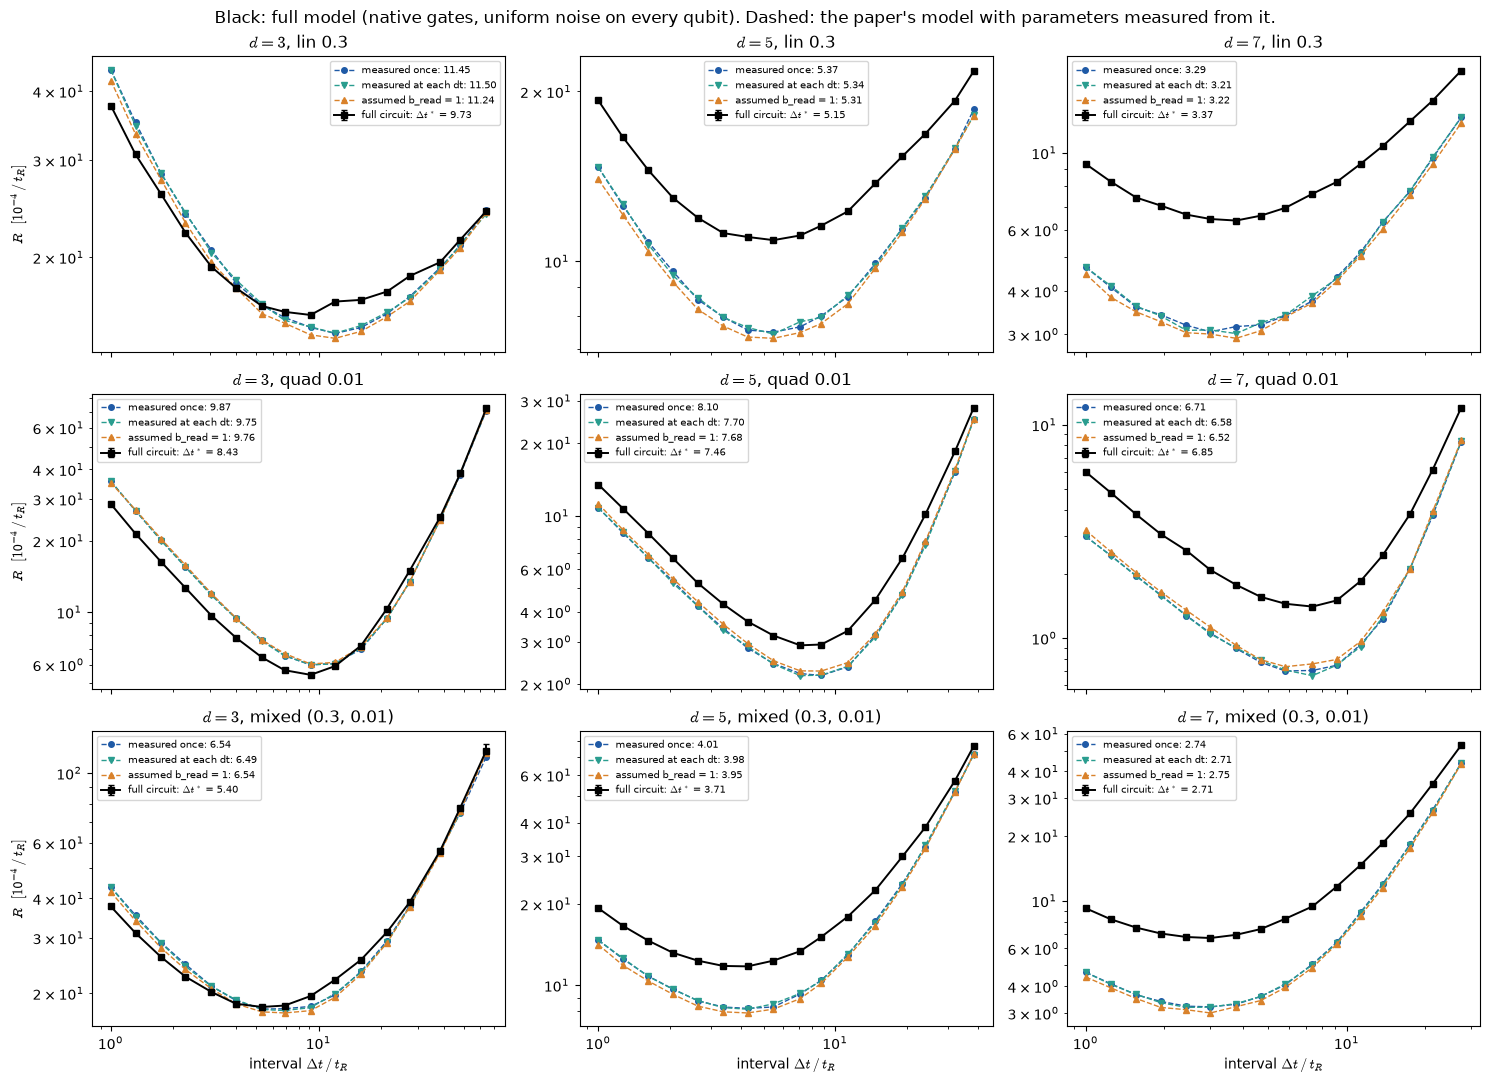

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex='col')
STY = {'measured once': (BLUE, 'o'), 'measured at each dt': (AQUA, 'v'), 'assumed b_read = 1': (ORANGE, '^')}
for j, d in enumerate(DISTANCES):
    for i, k in enumerate(KEYS):
        ax = axes[i, j]
        df = FULL[(d, k)]
        ax.errorbar(df.dt, df.r * 1e4, yerr=df.sr * 1e4, fmt='s-', ms=4, lw=1.4, color='k', capsize=2,
                    label=f"full circuit: $\\Delta t^*$ = {OPT[(d, k)]['dt_star']:.2f}")
        for name, (col, mk) in STY.items():
            p = PH[(d, k, name)]
            ax.plot(p.dt, p.r * 1e4, mk + '--', ms=4, lw=1, color=col,
                    label=f"{name}: {PHOPT[(d, k, name)]['dt_star']:.2f}")
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'$d = {d}$, {label(k)}')
        if j == 0:
            ax.set_ylabel(r'$R$  $[10^{-4}\,/\,t_R]$')
        if i == 2:
            ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
        ax.legend(fontsize=7)
fig.suptitle('Black: full model (native gates, uniform noise on every qubit). Dashed: the paper\'s model with parameters measured from it.')
fig.tight_layout()
fig.savefig(FIGDIR / '09_native_uniform_premise.png', dpi=130, bbox_inches='tight', facecolor='white')

## 5. The ladder: what each ingredient does to Δt\*

The same idle settings, gate noise, grid, seeds and shots in four notebooks, each adding one
ingredient. Read from cache; nothing is recomputed.

| column | gates | idle noise |
| --- | --- | --- |
| 07 | textbook | data only, once per interval |
| 07b | native | data only, once per interval |
| 08 | textbook | every qubit, through the round (7 layers) and the wait |
| 09 | native | every qubit, through the round (18 layers) and the wait |

In [10]:
def cached_curve(exp, d, key, extra=None):
    g, c = idle_of(key)
    rows = []
    for dt, R in dt_grid(d):
        F = N = 0
        for sd in SEEDS:
            if exp in (EXP07, EXP07B):
                p = dict(code='rotated', d=d, basis='X', dt=float(dt), rounds=int(R), gamma=float(g),
                         c=float(c), shots=SHOTS, seed=sd, **{k: float(v) for k, v in GATES.items()})
            else:
                p = dict(kind='full', d=d, dt=float(dt), R=R, gamma=float(g), c=float(c),
                         shots=SHOTS, seed=sd, **{k: float(v) for k, v in GATES.items()})
            p.update(extra or {})
            h = runcache.load(exp, p)
            assert h is not None, (exp, p)
            F, N = F + h['fails'], N + h['shots']
        r, sr = rate(F, N)
        rows.append(dict(dt=dt, R=R, pL=F / N, r=r, sr=sr))
    return pd.DataFrame(rows)


NATIVE07B = {'circuit': 'native: Selene-compiled gates, native_memory', 'rz_noise': False}
rows = []
for d in DISTANCES:
    for k in KEYS:
        o = {'07': optimum(cached_curve(EXP07, d, k)),
             '07b': optimum(cached_curve(EXP07B, d, k, NATIVE07B)),
             '08': optimum(cached_curve(EXP08, d, k, {'ancilla_idle': True})),
             '09': OPT[(d, k)]}
        row = {'d': d, 'idle': label(k)}
        row.update({f'dt* {n}': round(v['dt_star'], 2) for n, v in o.items()})
        row['native gates (07b/07)'] = f"{o['07b']['dt_star'] / o['07']['dt_star'] - 1:+.1%}"
        row['uniform noise (08/07)'] = f"{o['08']['dt_star'] / o['07']['dt_star'] - 1:+.1%}"
        row['both (09/07)'] = f"{o['09']['dt_star'] / o['07']['dt_star'] - 1:+.1%}"
        row['native, given uniform (09/08)'] = f"{o['09']['dt_star'] / o['08']['dt_star'] - 1:+.1%}"
        rows.append(row)
LADDER = pd.DataFrame(rows)
print(LADDER.to_string(index=False))

 d              idle  dt* 07  dt* 07b  dt* 08  dt* 09 native gates (07b/07) uniform noise (08/07) both (09/07) native, given uniform (09/08)
 3           lin 0.3    9.64    10.06   10.12    9.73                 +4.3%                 +5.0%        +0.9%                         -3.9%
 3         quad 0.01    8.05     8.16    8.25    8.43                 +1.3%                 +2.4%        +4.7%                         +2.3%
 3 mixed (0.3, 0.01)    5.10     5.16    5.50    5.40                 +1.2%                 +8.0%        +6.0%                         -1.8%
 5           lin 0.3    5.12     5.40    5.35    5.15                 +5.5%                 +4.6%        +0.7%                         -3.7%
 5         quad 0.01    6.77     6.95    7.19    7.46                 +2.7%                 +6.2%       +10.2%                         +3.8%
 5 mixed (0.3, 0.01)    3.55     3.66    3.80    3.71                 +3.1%                 +7.1%        +4.6%                         -2.4%
 7           

## 6. At H2's estimated ratio

07 §7b on this model: idle error over one round period at Δt = 1 of `1.1·p_2q` (07 §7's rough H2
estimate), all linear (`γ = 1.1·p_2q`) or all quadratic (`sin²√c = 1.1·p_2q`), Δt ≤ 12. Scaled noise at
d = 3, 5, 7 (2 × 100,000 shots); real H2-1E gate rates at d = 3, 5 (2 × 500,000).

**Caveat for the quadratic case.** Here the quadratic term is applied per layer (08's convention),
so over one round it costs about `c/L` (L = 18 layers), not `c`. The "all quadratic" rows therefore
charge far less idle noise inside the round than their label suggests, and the cost lands almost
entirely on the wait. The linear rows have no such issue: they add up in time.

In [11]:
Q1_REL = 1.1


def h2_key(fam, p2):
    q = Q1_REL * p2
    return ('lin', q / P2) if fam == 'lin' else ('quad', float(np.arcsin(np.sqrt(q)) ** 2) / P2)


CHECK = {'scaled x4.76': (GATES, (3, 5, 7), 100_000),
         'real H2': (H2_GATES, (3, 5), 500_000)}
jobs = []
for scale, (gates, ds, shots) in CHECK.items():
    for d in ds:
        grid = [(dt, R) for dt, R in dt_grid(d) if dt <= 12]
        for fam in ('lin', 'quad'):
            jobs += full_jobs(d, h2_key(fam, gates['p2']), gates=gates, shots=shots, grid=grid)
run_all(jobs)

rows = []
for scale, (gates, ds, shots) in CHECK.items():
    for d in ds:
        grid = [(dt, R) for dt, R in dt_grid(d) if dt <= 12]
        for fam in ('lin', 'quad'):
            df = curve(full_jobs(d, h2_key(fam, gates['p2']), gates=gates, shots=shots, grid=grid))
            ok = df[np.isfinite(df.r)].reset_index(drop=True)
            i = int(np.argmin(ok.r.values))
            z = (ok.r[0] - ok.r[i]) / np.hypot(ok.sr[0], ok.sr[i]) if i else 0.0
            rows.append({'noise': scale, 'd': d, 'idle': 'all linear' if fam == 'lin' else 'all quadratic',
                         'lowest dt': round(ok.dt[i], 2),
                         'gain over dt=1': f'{ok.r[0] / ok.r[i] - 1:+.1%} ({z:.1f} sigma)'})
H2N = pd.DataFrame(rows)
print(H2N.to_string(index=False))

216 jobs, 0 computed [0s]
       noise  d          idle  lowest dt      gain over dt=1
scaled x4.76  3    all linear       2.29  +12.3% (8.0 sigma)
scaled x4.76  3 all quadratic       1.32 +17.9% (20.1 sigma)
scaled x4.76  5    all linear       1.27   +1.1% (1.2 sigma)
scaled x4.76  5 all quadratic       1.27 +15.3% (17.3 sigma)
scaled x4.76  7    all linear       1.00   +0.0% (0.0 sigma)
scaled x4.76  7 all quadratic       1.25 +13.8% (12.5 sigma)
     real H2  3    all linear       2.29 +11.2% (17.4 sigma)
     real H2  3 all quadratic       1.32 +18.0% (18.2 sigma)
     real H2  5    all linear       1.00   +0.0% (0.0 sigma)
     real H2  5 all quadratic       1.27  +13.4% (4.7 sigma)


## 7. Findings

Each finding says where it comes from: **measured here**, **repo** (a choice made in this repo's
code) or **interpretation** (my reading, not tested).

**1. The full model behaves like 08.** (Measured here, §2–4.) Every part of 08's answer holds:
- an interior optimum on all 9 curves;
- readout error independent of Δt (±0.5%);
- data error = the Δt = 1 value combined with the wait's idle error (±0.4%);
- the prediction from one calibration lands +17% to +21% long at d = 3, +4% to +9% at d = 5 and
  −2% to +1% at d = 7, with `p_L` again underestimated more as d grows (0.94–1.09, 0.73–0.76, 0.51).

Native gates and a finer clock (18 layers instead of 7) change none of it.

**2. Measured `b_read` is slightly lower on native gates.** (Measured here, §2.) From gates alone
it is 0.99, 0.96 and 0.95 at d = 3, 5, 7 (08, textbook: 1.02, 0.99, 0.98). With linear dephasing it
is 1.05–1.09 (08: 1.08–1.15). Two things move it:
- the native single-qubit gates add data error, which raises `p_stab`;
- ancilla dephasing adds less readout error than in 08: 0.83× 08's rise at d = 3.

*Interpretation, consistent with the numbers:* in the native schedule an X-check ancilla spends a
smaller fraction of the round in `|+⟩`, the only state where a Z flips its result: about 0.59 of
the round, against 5/7 = 0.71 in the textbook layering.

**3. The ingredients interact: under linear idle noise their effects cancel.** (Measured here, §5.)
Starting from 07:
- native gates alone lengthen Δt\* by +4% to +6% (07b);
- uniform noise alone lengthens it by +3% to +5% (08);
- both together give −0.4% to +0.9%.

Given uniform noise, native gates *shorten* Δt\* by 2–4% under linear and mixed idle noise, and
lengthen it by 2–4% under quadratic. *Interpretation:* finding 2. On native gates the ancillas
spend less time exposed, which makes the round cheaper relative to idling. Under quadratic idle
noise, which costs almost nothing inside the round (finding 4), only the extra gate error remains,
which makes the round costlier. Across all nine settings, the full model's Δt\* lies within 14%
of 07's, and within 1% under linear idle noise.

**4. At H2's estimated ratio, the linear conclusion stands and the quadratic one depends on an
unresolved convention.** (Measured here, §6, plus an argument.)
- **Linear idle noise.** As in 07: a short wait helps only at d = 3 (Δt = 2.29, +11–12%).
  Nothing at d ≥ 5.
- **Quadratic idle noise.** Unlike 07, a short wait (Δt ≈ 1.3) now helps by 13–18% at every
  distance. This follows from the model, not from new physics. The quadratic term grows like
  time², and here it is applied per layer: 18 pieces of `t_R/18`. That charges only about c/18 of
  idle error inside a round, against `c` for one unbroken round. Short waits are therefore nearly
  free, and the optimum moves off Δt = 1.
- Which is right depends on whether the coherent phase behind the quadratic term is reset between
  layers on real hardware (interpretation: gates on the qubit may reset it; plain idling does not).
- **Do not quote the quadratic H2 rows** until that is settled. A single-qubit benchmark on the
  emulator, with idles of several lengths, with and without gates in between, would settle it.

### Limits
- Equal layer durations: measurement, transport and gates take the same `t_R/18` (an assumption).
  On ions, measurement and transport are slower.
- The ASAP schedule follows Selene's compiled program; H2's compiler may schedule differently.
- `Rz` noiseless (07b); 07's ×4.76 noise scale; 07's rough H2 idle estimate (repo).
- The `p_ij` estimator breaks down at one interval (d = 3, mixed, Δt = 64), dropped (§4).